# Assignment #5: A sentence embedder
**Author:** Diego Besada

Created using [Pierre Nugues' template](https://github.com/pnugues/edan20/blob/master/labs_2026/5-sbert.ipynb).

## Objectives

In this assignment, we implement a sentence embedder simplified from Reimers and Gurevych's [Sentence-BERT](https://arxiv.org/pdf/1908.10084). We build a transformer-based model that produces dense sentence embeddings and compare it against a baseline using mean GloVe embeddings.

The objectives are to:
* Write a program to embed sentences
* Use neural networks with PyTorch
* Train on the SNLI corpus and evaluate using cosine similarity

## Overview

We implement two techniques to vectorize sentences into dense vectors:
1. **Baseline**: Mean of GloVe word embeddings
2. **SBERT**: A transformer-based encoder with mean pooling and a logistic regression head

SBERT is one of the earliest transformer-based sentence vectorization algorithms: _Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks_ by Reimers and Gurevych (2019).

## Analysis of the Algorithms

The transformer encoder uses multi-head self-attention to produce context-aware word representations. We pool these into sentence vectors $\mathbf{u}$ and $\mathbf{v}$, then concatenate $[\mathbf{u}; \mathbf{v}; |\mathbf{u}-\mathbf{v}|]$ for classification.

## Modules

In [1]:
import torch
import torch.nn as nn
import regex as re
from tqdm import tqdm
import json
import matplotlib.pyplot as plt

Use a reduced dataset for development. Set `MINI_CORPUS = False` to train on the full dataset.

In [2]:
MINI_CORPUS = True
MINI_PERCENTAGE = 0.01

## Dataset: SNLI

The [SNLI corpus](https://nlp.stanford.edu/projects/snli/) contains ~500,000 sentence pairs labeled as entailment, neutral, or contradiction.

In [3]:
with open('train.jsonl', 'r') as f:
    dataset_snli = [json.loads(line) for line in f]

# Filter samples without agreement
dataset_str = [
    (s['sentence1'], s['sentence2'], s['gold_label'])
    for s in dataset_snli if s['gold_label'] != '-'
]
print(f"Loaded {len(dataset_str)} samples")

if MINI_CORPUS:
    dataset_str = dataset_str[:int(len(dataset_str) * MINI_PERCENTAGE)]
    print(f"Using {len(dataset_str)} samples (mini corpus)")

Loaded 549367 samples
Using 5493 samples (mini corpus)


## GloVe Embeddings

We use [GloVe 6B](https://nlp.stanford.edu/projects/glove/) embeddings: 400,000 words with 50-dimensional vectors.

In [4]:
def read_embeddings(file):
    embeddings = {}
    with open(file, encoding='utf8') as f:
        for line in f:
            values = line.strip().split()
            word = values[0]
            vector = torch.tensor(list(map(float, values[1:])), dtype=torch.float32)
            embeddings[word] = vector
    return embeddings

embeddings = read_embeddings('glove.6B.50d.txt')

glove_words = list(embeddings.keys())
glove = torch.stack(list(embeddings.values()))
d_model = glove.size()[1]

# Prepend special tokens
specials = ['[PAD]', '[UNK]', '[CLS]']
glove_words = specials + glove_words
glove = torch.vstack((torch.zeros((3, d_model)), glove))
print(f"GloVe: {glove.size()[0]} words, {d_model} dimensions")

GloVe: 400003 words, 50 dimensions


## Preprocessing

In [5]:
pattern = re.compile(r'\p{L}+|\p{N}+|\p{P}')

def tokenize(sentence, pattern, lc=True):
    if lc:
        sentence = sentence.lower()
    return re.findall(pattern, sentence)

dataset_tokens = [
    (tokenize(s1, pattern), tokenize(s2, pattern), label)
    for s1, s2, label in tqdm(dataset_str)
]

token2idx = {token: idx for idx, token in enumerate(glove_words)}
idx2token = {idx: token for token, idx in token2idx.items()}

labels = sorted(set(label for _, _, label in dataset_tokens))
label2idx = {label: idx for idx, label in enumerate(labels)}
idx2label = {idx: label for label, idx in label2idx.items()}
nbr_classes = len(labels)
print(f"Labels: {labels}")

100%|██████████| 5493/5493 [00:00<00:00, 85040.07it/s]

Labels: ['contradiction', 'entailment', 'neutral']


## Converting to Tensors

In [6]:
def convert_symbols(symbols, symbol2idx):
    if isinstance(symbols, str):
        return torch.tensor(symbol2idx[symbols], dtype=torch.long)
    return torch.LongTensor([symbol2idx.get(symbol, 1) for symbol in symbols])

dataset = [
    (convert_symbols(s1, token2idx),
     convert_symbols(s2, token2idx),
     convert_symbols(label, label2idx))
    for s1, s2, label in dataset_tokens
]
print(f"Dataset: {len(dataset)} samples")

Dataset: 5493 samples


## Embedding Layer

In [7]:
glove_embs = nn.Embedding(
    glove.size()[0], glove.size()[1], padding_idx=0
).from_pretrained(glove)

## Baseline: Mean of GloVe Embeddings

In [8]:
def mean_embs(input_idx, glove_embs):
    return glove_embs(input_idx).mean(dim=0)

def compute_cosine(v1, v2):
    norm1 = torch.linalg.norm(v1)
    norm2 = torch.linalg.norm(v2)
    if norm1 == 0 or norm2 == 0:
        return torch.tensor(0.0)
    return torch.dot(v1, v2) / (norm1 * norm2)

## Results: Baseline

In [9]:
cos_sim = {'entailment': 0.0, 'neutral': 0.0, 'contradiction': 0.0}
cnt = {'entailment': 0.0, 'neutral': 0.0, 'contradiction': 0.0}
for data in tqdm(dataset):
    cos_val = compute_cosine(
        mean_embs(data[0], glove_embs),
        mean_embs(data[1], glove_embs))
    class_name = idx2label[data[2].item()]
    cos_sim[class_name] += cos_val
    cnt[class_name] += 1

for key in cos_sim.keys():
    cos_sim[key] /= cnt[key]
cos_sim

100%|██████████| 5493/5493 [00:00<00:00, 45381.21it/s]


{'entailment': tensor(0.9453),
 'neutral': tensor(0.9385),
 'contradiction': tensor(0.9298)}

## SBERT Architecture

In [10]:
class SBERT(nn.Module):
    def __init__(self, nbr_classes, glove, d_model=50, nhead=5, num_layers=4):
        super().__init__()
        self.d_model = d_model
        self.embeddings = nn.Embedding(
            glove.size()[0], glove.size()[1], padding_idx=0
        ).from_pretrained(glove)
        self.encoder_layer = nn.TransformerEncoderLayer(d_model, nhead)
        self.transformer_encoder = nn.TransformerEncoder(
            self.encoder_layer, num_layers=num_layers
        )
        self.fc = nn.Linear(3 * d_model, nbr_classes)

    def forward(self, u, v):
        u = self.embeddings(u)
        u = self.transformer_encoder(u).mean(dim=0)
        v = self.embeddings(v)
        v = self.transformer_encoder(v).mean(dim=0)
        x = torch.cat((u, v, torch.abs(u - v)), dim=-1)
        return self.fc(x)

sbert = SBERT(nbr_classes, glove)

/var/folders/sh/nrl4s8h10g11mn7h7_f2hvh00000gn/T/ipykernel_60457/486764270.py:9: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(


## Training SBERT

In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(sbert.parameters(), lr=0.00002)

ce_train_loss = []
sbert.train()
for epoch in range(5):
    total_loss = 0
    for data in tqdm(dataset):
        optimizer.zero_grad()
        output = sbert(data[0], data[1])
        loss = loss_fn(output.unsqueeze(0), data[2].unsqueeze(0))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    epoch_loss = total_loss / len(dataset)
    ce_train_loss.append(epoch_loss)
    print(f'Epoch {epoch}, Loss: {epoch_loss:.4f}')

100%|██████████| 5493/5493 [01:02<00:00, 88.43it/s]


Epoch 0, Loss: 1.0417


100%|██████████| 5493/5493 [01:02<00:00, 87.54it/s]


Epoch 1, Loss: 0.9776


100%|██████████| 5493/5493 [01:02<00:00, 88.21it/s]


Epoch 2, Loss: 0.9417


100%|██████████| 5493/5493 [01:04<00:00, 85.74it/s]


Epoch 3, Loss: 0.9034


100%|██████████| 5493/5493 [01:04<00:00, 85.02it/s]

Epoch 4, Loss: 0.8798


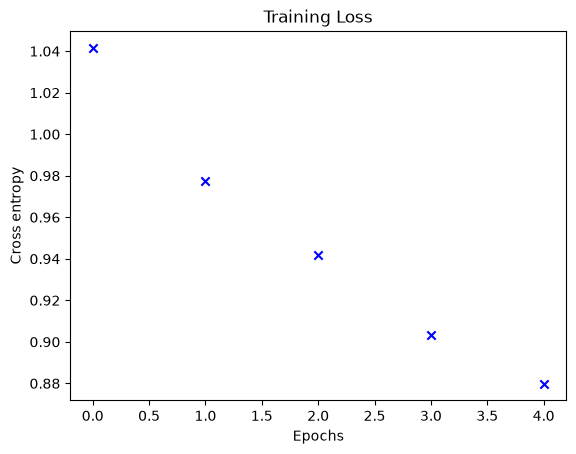

In [12]:
plt.scatter(range(len(ce_train_loss)), ce_train_loss, c='b', marker='x')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Cross entropy')
plt.show()

In [13]:
torch.save(sbert, 'sbert_mini.pt')

## Results: SBERT

In [14]:
sbert.eval()

def encode_sbert(model, token_indices):
    model.eval()
    with torch.no_grad():
        v = model.embeddings(token_indices)
        v = model.transformer_encoder(v).mean(dim=0)
        return v

cos_sim = {'entailment': 0.0, 'neutral': 0.0, 'contradiction': 0.0}
cnt = {'entailment': 0.0, 'neutral': 0.0, 'contradiction': 0.0}
for data in tqdm(dataset):
    cos_val = compute_cosine(
        encode_sbert(sbert, data[0]),
        encode_sbert(sbert, data[1]))
    class_name = idx2label[data[2].item()]
    cos_sim[class_name] += cos_val
    cnt[class_name] += 1

for key in cos_sim.keys():
    cos_sim[key] /= cnt[key]
cos_sim

100%|██████████| 5493/5493 [00:12<00:00, 428.88it/s]


{'entailment': tensor(0.6633),
 'neutral': tensor(0.5062),
 'contradiction': tensor(0.4496)}

## Comparing the Two Approaches

We apply both the baseline (mean GloVe) and SBERT embeddings to three sentences and compare their cosine similarity matrices.

In [15]:
import numpy as np

sentences = [
    "The weather is lovely today.",
    "It's so sunny outside!",
    "He drove to the stadium.",
]

indexed_sents = [convert_symbols(tokenize(sent, pattern), token2idx) for sent in sentences]

# Baseline embeddings
baseline_embs = [mean_embs(sent, glove_embs) for sent in indexed_sents]

# SBERT embeddings
sbert_embs = [encode_sbert(sbert, sent) for sent in indexed_sents]

# Cosine similarity matrices
baseline_matrix = torch.tensor([
    [compute_cosine(s1, s2) for s2 in baseline_embs]
    for s1 in baseline_embs
])

sbert_matrix = torch.tensor([
    [compute_cosine(s1, s2) for s2 in sbert_embs]
    for s1 in sbert_embs
])

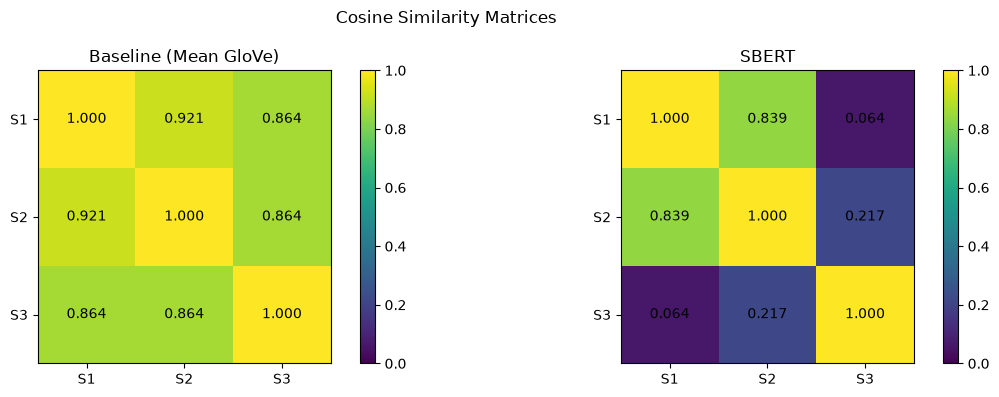

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

im1 = ax1.imshow(baseline_matrix.numpy(), vmin=0, vmax=1.0)
ax1.set_title('Baseline (Mean GloVe)')
ax1.set_xticks(range(3))
ax1.set_yticks(range(3))
ax1.set_xticklabels(['S1', 'S2', 'S3'])
ax1.set_yticklabels(['S1', 'S2', 'S3'])
for i in range(3):
    for j in range(3):
        ax1.text(j, i, f'{baseline_matrix[i,j]:.3f}', ha='center', va='center')
plt.colorbar(im1, ax=ax1)

im2 = ax2.imshow(sbert_matrix.numpy(), vmin=0.0, vmax=1.0)
ax2.set_title('SBERT')
ax2.set_xticks(range(3))
ax2.set_yticks(range(3))
ax2.set_xticklabels(['S1', 'S2', 'S3'])
ax2.set_yticklabels(['S1', 'S2', 'S3'])
for i in range(3):
    for j in range(3):
        ax2.text(j, i, f'{sbert_matrix[i,j]:.3f}', ha='center', va='center')
plt.colorbar(im2, ax=ax2)

plt.suptitle('Cosine Similarity Matrices')
plt.tight_layout()
plt.show()

The baseline's mean-pooling of GloVe vectors collapses all sentences into a narrow similarity range, making it useless for discrimination. SBERT's transformer encoder preserves contextual meaning: the model assigns high similarity to sentences 1 and 2 despite zero lexical overlap, because both describe favorable weather. Sentence 3, semantically unrelated, receives low similarity to both. This demonstrates that SBERT captures propositional content, not just word distribution.